In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import os
import xarray as xr
import xcdat as xc

In [3]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as mticker
import pandas as pd

In [4]:
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

ERROR 1: PROJ: proj_create_from_database: Open of /g/data/xp65/public/./apps/med_conda/envs/analysis3-25.09/share/proj failed


In [5]:
import cmocean
from scipy import stats

In [6]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 14
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 0.8
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [7]:
def plot_decorator():
    ax = plt.gca()
    
    # Minor ticks
    # ax.minorticks_on()
    # plt.tick_params(which='minor', axis='x', bottom=False)
    
    # Grid (light, behind data)
    ax.grid(color='gray', lw=0.4, alpha=0.1)
    
    # Remove top/right spines (Nature style)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Tight layout
    # plt.tight_layout()

In [8]:
from matplotlib.colors import BoundaryNorm as BM
# from matplotlib.colors import LogNorm as LM
import matplotlib.patches as mpatches

In [9]:
import regionmask

In [10]:
def plot_background(ax, draw_labels=False, draw_ipcc_regions=False):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    # ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=draw_labels,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    if draw_ipcc_regions:
        ar6_reg = regionmask.defined_regions.ar6.all

        # Plot the region boundaries, passing the same 'ax'
        # Use 'line_kws' to customize line properties (color, thickness, etc.)
        ar6_reg.plot_regions(
            ax=ax,
            line_kws=dict(color='black', lw=1.0, alpha=0.4),
            text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
            add_label=False, # Set to True to add text labels for regions
        )
    return ax




def plot_maps(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='///', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] > 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] <= 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_map(x, y, z, title, label, cmap, levels, add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        if hatch_type == 'insig':
            pval_plot = np.ma.masked_less_equal(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='//', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval > 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        elif hatch_type == 'sig':
            pval_plot = np.ma.masked_greater(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='..', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval <= 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [11]:
def plot_maps_no_proj(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_colorbar=True, auto_aspect=False, draw_clabel=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, sharex=True, sharey=True)
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle')
    
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            cs = axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, alpha=0.5)
            if draw_clabel:
                axlist[i].clabel(cs, inline=True, fontsize=8)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])
    return fig, axlist

In [12]:
def plot_maps_tele_delta(x, y, z, titles, labels, cmap, levels, pval = [], pval2=[], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 1.5)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
        if pval2 != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 1.5)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='xxx', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval[i] <= 0.05, True, False)
            # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_tele_delta(x, y, z, title, label, cmap, levels, add_sign=False, pval = [],  pval2 = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        pval_plot = np.ma.masked_less_equal(pval, 1)
        ax.pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
        pval_plot = np.ma.masked_less_equal(pval2, 1)
        ax.pcolor(x, y, pval_plot, alpha = 0., hatch='xxx', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [13]:
import sys

In [14]:
# sys.path.append('./PhD/enso_teleconnection_robustness/')

In [15]:
from functions import preproc_funcs as funcs

In [16]:
import matplotlib.colors as mcolors

In [17]:
import sys

In [18]:
from functions import preproc_funcs as funcs

In [19]:
base_path = "/g/data/if69/as8561/data/enso_tele_robustness"

smile_models = [
    'ACCESS-ESM1-5', 'CESM1-CAM5', 'CSIRO-Mk3-6-0',
    'CanESM2', 'CanESM5_p1', 'GFDL-CM3', 'GFDL-ESM2M',
    'GFDL-SPEAR-MED', 'MIROC6', 'MPI-ESM',
]

# --- Precipitation ---
ds_pr_rean  = xr.open_dataset(f"{base_path}/pr_rean_composites.nc")
ds_pr_cmip6 = xr.open_dataset(f"{base_path}/res/pr_enso_comp/cmip6_composites.nc")
ds_pr_smile = {m: xr.open_dataset(f"{base_path}/res/pr_enso_comp/{m}_composites.nc")
               for m in smile_models}

# --- Temperature ---
ds_ts_rean  = xr.open_dataset(f"{base_path}/tas_composites.nc")
ds_ts_cmip6 = xr.open_dataset(f"{base_path}/res/ts_enso_comp/cmip6_composites.nc")
ds_ts_smile = {m: xr.open_dataset(f"{base_path}/res/ts_enso_comp/{m}_composites.nc")
               for m in smile_models}

In [20]:
import regionmask

ar6_regions = regionmask.defined_regions.ar6.land

# Create masks on each grid
ar6_mask_rean  = ar6_regions.mask(ds_pr_rean.lon,  ds_pr_rean.lat)
ar6_mask_ts_obs = ar6_regions.mask(ds_ts_rean.lon, ds_ts_rean.lat)
ar6_mask_cmip6 = ar6_regions.mask(ds_pr_cmip6.lon, ds_pr_cmip6.lat)
ar6_mask_smile = ar6_regions.mask(ds_pr_smile['ACCESS-ESM1-5'].lon,
                                   ds_pr_smile['ACCESS-ESM1-5'].lat)

In [21]:
def regional_mean(da, mask, region_num):
    return da.where(mask == region_num).mean(['lat', 'lon'])

In [22]:
records = []

for r in ar6_regions:
    # Historical EN/LN strength from reanalysis
    en_pr = float(np.abs(regional_mean(ds_pr_rean.en.mean('time'), ar6_mask_rean, r.number)))
    ln_pr = float(np.abs(regional_mean(ds_pr_rean.ln.mean('time'), ar6_mask_rean, r.number)))
    en_ts = float(np.abs(regional_mean(ds_ts_rean.en.mean('time'), ar6_mask_ts_obs, r.number)))
    ln_ts = float(np.abs(regional_mean(ds_ts_rean.ln.mean('time'), ar6_mask_ts_obs, r.number)))

    records.append(dict(
        number      = r.number,
        abbrev      = r.abbrev,
        name        = r.name,
        en_pr_hist  = en_pr,
        ln_pr_hist  = ln_pr,
        en_ts_hist  = en_ts,
        ln_ts_hist  = ln_ts,
        mean_pr     = (en_pr + ln_pr) / 2,
        mean_ts     = (en_ts + ln_ts) / 2,
    ))

df_regions = pd.DataFrame(records).sort_values('mean_pr', ascending=False)
print(df_regions[['abbrev', 'name', 'en_pr_hist', 'ln_pr_hist', 
                   'en_ts_hist', 'ln_ts_hist']].to_string())

   abbrev                    name  en_pr_hist  ln_pr_hist  en_ts_hist  ln_ts_hist
39    NAU             N.Australia    0.497827    1.014375    0.012383    0.079546
10    NSA         N.South-America    0.586044    0.850081    0.266028    0.211163
41    EAU             E.Australia    0.167010    0.818468    0.221166    0.159520
37    SAS                  S.Asia    0.421525    0.496993    0.142994    0.101286
38    SEA                S.E.Asia    0.463894    0.406138    0.104105    0.057148
26   ESAF       E.Southern-Africa    0.273237    0.589810    0.212364    0.099581
6     NCA       N.Central-America    0.428144    0.251465    0.048329    0.102775
32    WCA                W.C.Asia    0.290186    0.372969    0.082970    0.062710
40    CAU             C.Australia    0.037777    0.567484    0.222067    0.157523
11    NES       N.E.South-America    0.298899    0.287760    0.177907    0.091199
7     SCA       S.Central-America    0.189278    0.391332    0.243545    0.266511
43     NZ       

In [23]:
selected_abbrevs = ['NAU', 'NSA', 'CAU', 'EAU', 'NWS', 'RAR', 'NCA', 'SEA']
df_selected = df_regions[df_regions.abbrev.isin(selected_abbrevs)].set_index('abbrev')
print(df_selected[['name', 'en_pr_hist', 'ln_pr_hist', 'en_ts_hist', 'ln_ts_hist']])

                     name  en_pr_hist  ln_pr_hist  en_ts_hist  ln_ts_hist
abbrev                                                                   
NAU           N.Australia    0.497827    1.014375    0.012383    0.079546
NSA       N.South-America    0.586044    0.850081    0.266028    0.211163
EAU           E.Australia    0.167010    0.818468    0.221166    0.159520
SEA              S.E.Asia    0.463894    0.406138    0.104105    0.057148
NCA     N.Central-America    0.428144    0.251465    0.048329    0.102775
CAU           C.Australia    0.037777    0.567484    0.222067    0.157523
RAR        Russian-Arctic    0.218722    0.206149    0.468896    0.171666
NWS     N.W.South-America    0.195708    0.172906    0.564541    0.419281


## Selected AR6 Regions for ENSO Teleconnection Emergence Analysis

| Abbrev | Name | Rationale |
|--------|------|-----------|
| **NAU** | N. Australia | Strong precipitation asymmetry (LN >> EN); weak temperature signal; canonical ENSO teleconnection region |
| **NSA** | N. South America | Strong precipitation in both phases; moderate temperature; near-symmetric — good reference case |
| **CAU** | C. Australia | Extreme precipitation asymmetry — near-zero EN, very strong LN; tests whether models capture one-sided teleconnections |
| **EAU** | E. Australia | Strong LN precipitation, moderate EN temperature; intermediate asymmetry case |
| **NWS** | N.W. South America | Strong temperature signal in both phases, moderate precipitation — temperature-dominated teleconnection |
| **RAR** | Russian Arctic | Strong EN temperature, weak precipitation — Arctic amplification signal; tests high-latitude emergence |
| **NCA** | N. Central America | EN-dominant precipitation — opposite polarity to Australia; tests whether models agree on sign |
| **SEA** | S.E. Asia | Moderate both phases — monsoon region with complex ENSO interaction |

**Selection criteria:** Regions were chosen to represent four distinct teleconnection 
behaviours — (1) symmetric response in both phases, (2) strong asymmetry between EN 
and LN, (3) precipitation-dominated response, and (4) temperature-dominated response 
— as well as geographic diversity across tropical, subtropical, and high-latitude zones.

In [24]:
selected_regions = {r.abbrev: r.number for r in ar6_regions 
                    if r.abbrev in selected_abbrevs}
print(selected_regions)

{'NCA': 6, 'NWS': 9, 'NSA': 10, 'RAR': 28, 'SEA': 38, 'NAU': 39, 'CAU': 40, 'EAU': 41}


In [25]:
def extract_regional_ts(ds, mask, region_dict, variables=['en', 'ln', 'neut']):
    """Extract regional mean time series for selected regions."""
    result = {}
    for abbrev, rnum in region_dict.items():
        result[abbrev] = {}
        for var in variables:
            result[abbrev][var] = ds[var].where(mask == rnum).mean(['lat', 'lon'])
    return result

# CMIP6 — mean over models
regional_pr_cmip6 = extract_regional_ts(ds_pr_cmip6, ar6_mask_cmip6, selected_regions)
regional_ts_cmip6 = extract_regional_ts(ds_ts_cmip6, ar6_mask_cmip6, selected_regions)

In [26]:
from tqdm.auto import tqdm

In [27]:
regional_pr_smile = {m: extract_regional_ts(
                        ds_pr_smile[m].convert_calendar('standard', use_cftime=False), 
                        ar6_mask_smile, selected_regions)
                     for m in tqdm(smile_models, desc='PR SMILEs')}

regional_ts_smile = {m: extract_regional_ts(
                        ds_ts_smile[m].convert_calendar('standard', use_cftime=False),
                        ar6_mask_smile, selected_regions)
                     for m in tqdm(smile_models, desc='TS SMILEs')}

PR SMILEs:   0%|          | 0/10 [00:00<?, ?it/s]

TS SMILEs:   0%|          | 0/10 [00:00<?, ?it/s]

In [28]:
regional_pr_rean = extract_regional_ts(ds_pr_rean, ar6_mask_rean,  selected_regions)
regional_ts_obs  = extract_regional_ts(ds_ts_rean, ar6_mask_ts_obs, selected_regions)

In [29]:
reg = 'NAU'
print("PR CMIP6 EN:", regional_pr_cmip6[reg]['en'])
print("PR SMILE ACCESS EN:", regional_pr_smile['ACCESS-ESM1-5'][reg]['en'])
print("PR REAN EN:", regional_pr_rean[reg]['en'])
print("TS OBS EN:", regional_ts_obs[reg]['en'])

PR CMIP6 EN: <xarray.DataArray 'en' (model: 46, time: 250)> Size: 46kB
array([[        nan,         nan,         nan, ...,         nan,
                nan,         nan],
       [        nan,         nan,         nan, ...,         nan,
                nan,         nan],
       [        nan, -0.66902846,         nan, ...,         nan,
        -0.5200251 ,         nan],
       ...,
       [        nan,         nan,         nan, ...,         nan,
        -0.8862521 ,         nan],
       [        nan,         nan,         nan, ...,         nan,
        -0.77104557,         nan],
       [        nan, -0.15941428,         nan, ...,         nan,
                nan,         nan]], dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 2kB 1850-06-01 1851-06-01 ... 2099-06-01
  * model    (model) <U16 3kB 'CanESM5' 'CanESM5-CanOE' ... 'BCC-CSM2-MR'
PR SMILE ACCESS EN: <xarray.DataArray 'en' (model: 40, time: 252)> Size: 81kB
array([[        nan,         nan,         nan, ...,         

In [30]:
def compute_smile_stats(regional_smile, region, var):
    """
    For each SMILE model compute ensemble mean and std over time.
    Then average across SMILE models.
    """
    means, ivs = [], []
    for m in smile_models:
        da = regional_smile[m][region][var]
        means.append(da.mean('model', skipna=True))   # ensemble mean
        ivs.append(da.std('model',  skipna=True))     # IV
    
    # Stack across SMILE models
    means = xr.concat(means, dim='smile_model')
    ivs   = xr.concat(ivs,   dim='smile_model')
    
    return means.mean('smile_model'), ivs.mean('smile_model')  # avg across models

In [31]:
def compute_cmip6_mmm(regional_cmip6, region, var):
    da = regional_cmip6[region][var]
    return da.mean('model', skipna=True)

In [32]:
def compute_obs_envelope(da_obs, baseline_start=1950, baseline_end=2014, duration=30, gap=1):
    """
    Rolling 30-year mean of obs EN/LN composite.
    Returns baseline value and std across windows as uncertainty.
    """
    # Baseline value — mean of non-NaN years in baseline
    baseline_val = float(da_obs.sel(
        time=slice(str(baseline_start), str(baseline_end))
    ).mean('time', skipna=True))
    
    # Rolling windows
    years     = da_obs.time.dt.year.values
    all_years = np.arange(1900, baseline_end - duration + 2, gap)
    
    roll_means = []
    for yr in all_years:
        subset = da_obs.sel(time=slice(str(yr), str(yr + duration - 1)))
        val = float(subset.mean('time', skipna=True))
        roll_means.append(val)
    
    roll_means = np.array(roll_means)
    roll_means = roll_means[~np.isnan(roll_means)]
    
    return baseline_val, np.std(roll_means)

In [33]:
reg, var = 'NAU', 'en'

smile_mean, smile_iv = compute_smile_stats(regional_pr_smile, reg, var)
cmip6_mmm            = compute_cmip6_mmm(regional_pr_cmip6,   reg, var)
obs_base, obs_std    = compute_obs_envelope(regional_pr_rean[reg][var])

print(f"SMILE mean range: {float(smile_mean.min()):.3f} to {float(smile_mean.max()):.3f}")
print(f"SMILE IV range:   {float(smile_iv.min()):.3f} to {float(smile_iv.max()):.3f}")
print(f"CMIP6 MMM range:  {float(cmip6_mmm.min()):.3f} to {float(cmip6_mmm.max()):.3f}")
print(f"Obs baseline:     {obs_base:.3f}")
print(f"Obs uncertainty:  {obs_std:.3f}")

SMILE mean range: -2.010 to 0.760
SMILE IV range:   0.068 to 0.510
CMIP6 MMM range:  -1.297 to -0.051
Obs baseline:     -0.563
Obs uncertainty:  0.110


In [34]:
def plot_emergence_ts(regional_pr_smile, regional_ts_smile,
                      regional_pr_cmip6, regional_ts_cmip6,
                      regional_pr_rean, regional_ts_obs,
                      region, baseline_start=1950, baseline_end=2014):
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
    axes = axes.flatten()

    configs = [
        (regional_pr_smile, regional_pr_cmip6, regional_pr_rean, 'en',  'PR — El Niño',  'mm/day', axes[0]),
        (regional_pr_smile, regional_pr_cmip6, regional_pr_rean, 'ln',  'PR — La Niña',  'mm/day', axes[1]),
        (regional_ts_smile, regional_ts_cmip6, regional_ts_obs,  'en',  'TAS — El Niño', '°C',     axes[2]),
        (regional_ts_smile, regional_ts_cmip6, regional_ts_obs,  'ln',  'TAS — La Niña', '°C',     axes[3]),
    ]

    for smile_dict, cmip6_dict, obs_dict, var, title, units, ax in configs:

        # --- SMILE ensemble mean and IV ---
        smile_mean, smile_iv = compute_smile_stats(smile_dict, region, var)
        time_smile = smile_mean.time.dt.year.values

        ax.plot(time_smile, smile_mean, color='steelblue', lw=1.5, label='SMILE mean')
        ax.fill_between(time_smile,
                        smile_mean - smile_iv,
                        smile_mean + smile_iv,
                        color='steelblue', alpha=0.2, label='SMILE IV (±1σ)')

        # --- CMIP6 MMM ---
        cmip6_mmm = compute_cmip6_mmm(cmip6_dict, region, var)
        time_cmip6 = cmip6_mmm.time.dt.year.values
        ax.plot(time_cmip6, cmip6_mmm, color='tomato', lw=1.5,
                linestyle='--', label='CMIP6 MMM')

        # --- Obs baseline and uncertainty envelope ---
        obs_base, obs_std = compute_obs_envelope(obs_dict[region][var])
        ax.axhline(obs_base, color='k', lw=1.2, label='Obs baseline')
        ax.axhspan(obs_base - obs_std, obs_base + obs_std,
                   color='k', alpha=0.1, label='Obs uncertainty (±1σ)')

        # --- Baseline period marker ---
        ax.axvspan(baseline_start, baseline_end,
                   color='grey', alpha=0.08, linestyle='--')

        ax.set_title(f'{region} — {title}')
        ax.set_ylabel(units)
        ax.axhline(0, color='k', lw=0.5, linestyle=':')
        ax.grid(True, alpha=0.3)

    axes[0].legend(fontsize=8, ncol=2)
    axes[-1].set_xlabel('Year')
    axes[-2].set_xlabel('Year')

    fig.suptitle(f'ENSO Teleconnection Emergence — {region}', fontsize=13, y=1.01)
    plt.tight_layout()

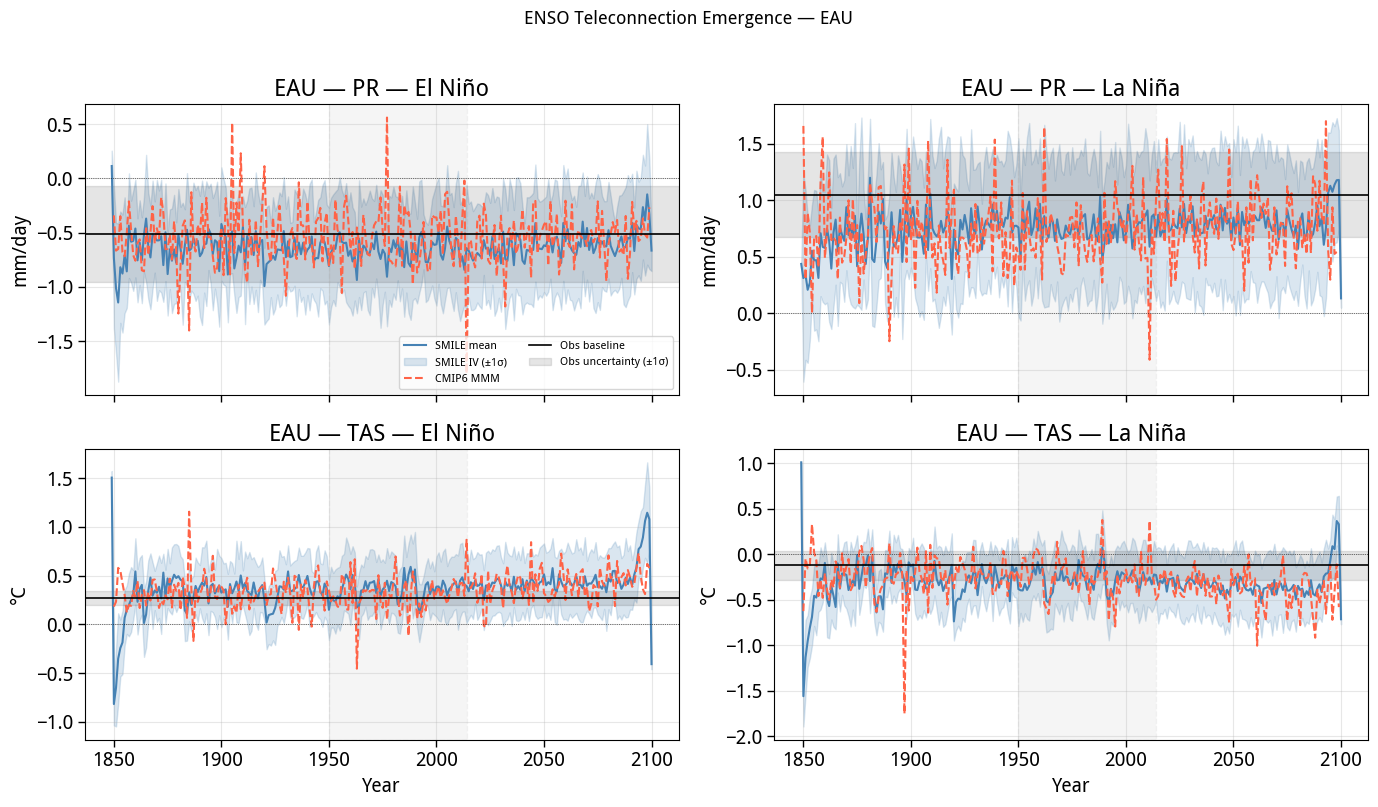

In [35]:
fig = plot_emergence_ts(
    regional_pr_smile=regional_pr_smile,
    regional_ts_smile=regional_ts_smile,
    regional_pr_cmip6=regional_pr_cmip6,
    regional_ts_cmip6=regional_ts_cmip6,
    regional_pr_rean=regional_pr_rean,
    regional_ts_obs=regional_ts_obs,
    region=selected_abbrevs[3]
)
plt.show()

{'whiskers': [<matplotlib.lines.Line2D at 0x7f4e10394b10>,
 'caps': [<matplotlib.lines.Line2D at 0x7f4e10395f10>,
 'boxes': [<matplotlib.lines.Line2D at 0x7f4e10394350>,
 'medians': [<matplotlib.lines.Line2D at 0x7f4e103971d0>,
 'fliers': [<matplotlib.lines.Line2D at 0x7f4e10361010>,
 'means': []}

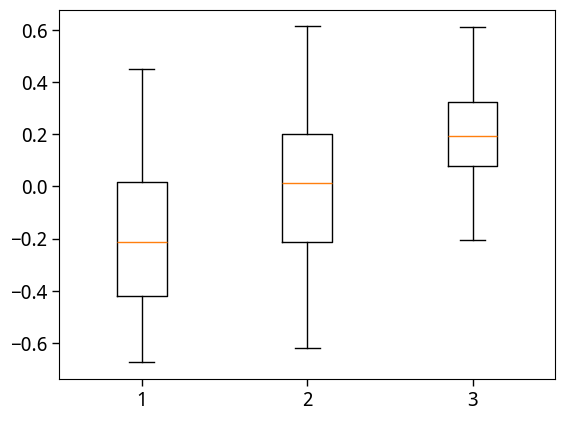

In [44]:
plt.boxplot([regional_ts_obs['EAU']['ln'].dropna('time'), regional_ts_obs['EAU']['neut'].dropna('time'), regional_ts_obs['EAU']['en'].dropna('time')])